In [1]:
#Data Manipulation specific
import numpy as np
import pandas as pd
import xarray as xr
#import scipy.stats as stats
#from scipy import signal
from netCDF4 import Dataset
#from osgeo import gdal
#Visualisation specific
#import seaborn as sns 
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

import rasterio
from rasterio.transform import from_origin


/home/anas.oubaha/.local/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
!free -g

              total        used        free      shared  buff/cache   available
Mem:            376          67         131           1         177         304
Swap:             0           0           0


**Read NC data**

In [2]:
# Load dataset
ds = xr.open_dataset('data/vv.nc', engine="netcdf4")  # Load NetCDF file
ds = ds.sel(latitude=slice(45, 15))
ds = ds.sel(longitude=slice(-15, 0))
ds = ds[['w']] #keep only the variable z
ds

<xarray.Dataset>
Dimensions:         (valid_time: 408, pressure_level: 37, latitude: 121,
                     longitude: 61)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 1991-01-01 ... 2024-12-01
  * pressure_level  (pressure_level) float64 1e+03 975.0 950.0 ... 3.0 2.0 1.0
  * latitude        (latitude) float64 45.0 44.75 44.5 44.25 ... 15.5 15.25 15.0
  * longitude       (longitude) float64 -15.0 -14.75 -14.5 ... -0.5 -0.25 0.0
Data variables:
    w               (valid_time, pressure_level, latitude, longitude) float32 ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

**Seasonal VV anomalies and p_values**

In [3]:
import pandas as pd
import numpy as np
import xarray as xr
from scipy.stats import ttest_ind

# Convert time to datetime
ds = ds.assign_coords(date=pd.to_datetime(ds['valid_time'].data.astype(str), format='ISO8601'))

drought_years = [1994, 1995, 1999, 2000, 2001, 2005, 2016, 2019, 2020, 2021, 2022, 2023]

# Lists to collect results
anomaly_list = []
pval_list = []

for p in ds['pressure_level'].values:
    dsh = ds.sel(pressure_level=p).squeeze()
    df = dsh['w'].to_dataframe().reset_index()
    
    df['year'] = df['valid_time'].dt.year
    df['month'] = df['valid_time'].dt.month
    df['season'] = np.select(
        [df['month'].isin([12, 1, 2]), df['month'].isin([3, 4, 5]),
         df['month'].isin([6, 7, 8]), df['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON']
    )
    df['season_year'] = df['year']
    df.loc[df['month'] == 12, 'season_year'] += 1

    seasonal = df.groupby(['latitude', 'longitude', 'season_year', 'season'])['w'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['w'].mean().reset_index()
    clim.rename(columns={'w': 'w_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['w_anomaly'] = merged['w'] - merged['w_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['w_anomaly']].to_xarray()['w_anomaly']
    da = da.expand_dims(pressure_level=[p])
    anomaly_list.append(da)

    # Statistical testing (same as before)
    pivot = merged.pivot_table(index='season_year', columns=['latitude', 'longitude', 'season'], values='w_anomaly')
    drought_vals = pivot.loc[pivot.index.isin(drought_years)]
    non_drought_vals = pivot.loc[~pivot.index.isin(drought_years)]

    t_vals, p_vals = ttest_ind(drought_vals, non_drought_vals, axis=0, equal_var=False, nan_policy='omit')
    p_df = pd.DataFrame([p_vals], columns=pivot.columns).T.reset_index()
    p_df.columns = ['latitude', 'longitude', 'season', 'p_value']
    p_df['pressure_level'] = p

    # Merge p-values back into the full merged DataFrame (season-year level)
    merged_with_p = pd.merge(merged, p_df, on=['latitude', 'longitude', 'season'], how='left')

    # Use same indexing as anomaly for correct shape
    p_da = merged_with_p.set_index(['date', 'latitude', 'longitude'])[['p_value']].to_xarray()['p_value']
    p_da = p_da.expand_dims(pressure_level=[p])
    pval_list.append(p_da)

# Final xarray outputs
anomaly_all_levels = xr.concat(anomaly_list, dim='pressure_level').sortby('pressure_level')
pval_all_levels = xr.concat(pval_list, dim='pressure_level').sortby('pressure_level')

anomaly_ds = xr.Dataset({'w_anomaly': anomaly_all_levels})
pval_ds = xr.Dataset({'p_value': pval_all_levels})


In [4]:
anomaly_ds

<xarray.Dataset>
Dimensions:         (pressure_level: 37, date: 137, latitude: 121, longitude: 61)
Coordinates:
  * pressure_level  (pressure_level) float64 1.0 2.0 3.0 ... 950.0 975.0 1e+03
  * date            (date) object 'DJF_1991' 'DJF_1992' ... 'SON_2024'
  * latitude        (latitude) float64 15.0 15.25 15.5 15.75 ... 44.5 44.75 45.0
  * longitude       (longitude) float64 -15.0 -14.75 -14.5 ... -0.5 -0.25 0.0
Data variables:
    w_anomaly       (pressure_level, date, latitude, longitude) float32 -2.38...

In [5]:
# Load dataset
dsu = xr.open_dataset('data/u.nc', engine="netcdf4")  # Load NetCDF file
dsu = dsu.sel(latitude=slice(45, 15))
dsu = dsu.sel(longitude=slice(-15, 0))
dsu = dsu[['u']] #keep only the variable u

dsv = xr.open_dataset('data/v.nc', engine="netcdf4")  # Load NetCDF file
dsv = dsv.sel(latitude=slice(45, 15))
dsv = dsv.sel(longitude=slice(-15, 0))
dsv = dsv[['v']] #keep only the variable v
dsu

<xarray.Dataset>
Dimensions:         (valid_time: 408, pressure_level: 37, latitude: 121,
                     longitude: 61)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 1991-01-01 ... 2024-12-01
  * pressure_level  (pressure_level) float64 1e+03 975.0 950.0 ... 3.0 2.0 1.0
  * latitude        (latitude) float64 45.0 44.75 44.5 44.25 ... 15.5 15.25 15.0
  * longitude       (longitude) float64 -15.0 -14.75 -14.5 ... -0.5 -0.25 0.0
Data variables:
    u               (valid_time, pressure_level, latitude, longitude) float32 ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [6]:
# Convert time to datetime
dsv = dsv.assign_coords(date=pd.to_datetime(dsv['valid_time'].data.astype(str), format='ISO8601'))

# Lists to collect results
vanomaly_list = []

for p in dsu['pressure_level'].values:
    dsvh = dsv.sel(pressure_level=p).squeeze()
    dfv = dsvh['v'].to_dataframe().reset_index()
    
    dfv['year'] = dfv['valid_time'].dt.year
    dfv['month'] = dfv['valid_time'].dt.month
    dfv['season'] = np.select(
        [dfv['month'].isin([12, 1, 2]), dfv['month'].isin([3, 4, 5]),
         dfv['month'].isin([6, 7, 8]), dfv['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON']
    )
    dfv['season_year'] = dfv['year']
    dfv.loc[dfv['month'] == 12, 'season_year'] += 1

    seasonal = dfv.groupby(['latitude', 'longitude', 'season_year', 'season'])['v'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['v'].mean().reset_index()
    clim.rename(columns={'v': 'v_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['v_anomaly'] = merged['v'] - merged['v_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['v_anomaly']].to_xarray()['v_anomaly']
    da = da.expand_dims(pressure_level=[p])
    vanomaly_list.append(da)

# Final xarray outputs
vanomaly_all_levels = xr.concat(vanomaly_list, dim='pressure_level').sortby('pressure_level')

vanomaly_ds = xr.Dataset({'v_anomaly': vanomaly_all_levels})

In [7]:
# Convert time to datetime
dsu = dsu.assign_coords(date=pd.to_datetime(dsu['valid_time'].data.astype(str), format='ISO8601'))

# Lists to collect results
uanomaly_list = []

for p in dsu['pressure_level'].values:
    dsuh = dsu.sel(pressure_level=p).squeeze()
    dfu = dsuh['u'].to_dataframe().reset_index()
    
    dfu['year'] = dfu['valid_time'].dt.year
    dfu['month'] = dfu['valid_time'].dt.month
    dfu['season'] = np.select(
        [dfu['month'].isin([12, 1, 2]), dfu['month'].isin([3, 4, 5]),
         dfu['month'].isin([6, 7, 8]), dfu['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON']
    )
    dfu['season_year'] = dfu['year']
    dfu.loc[dfu['month'] == 12, 'season_year'] += 1

    seasonal = dfu.groupby(['latitude', 'longitude', 'season_year', 'season'])['u'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['u'].mean().reset_index()
    clim.rename(columns={'u': 'u_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['u_anomaly'] = merged['u'] - merged['u_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['u_anomaly']].to_xarray()['u_anomaly']
    da = da.expand_dims(pressure_level=[p])
    uanomaly_list.append(da)

# Final xarray outputs
uanomaly_all_levels = xr.concat(uanomaly_list, dim='pressure_level').sortby('pressure_level')

uanomaly_ds = xr.Dataset({'u_anomaly': uanomaly_all_levels})

In [8]:
uanomaly_ds

<xarray.Dataset>
Dimensions:         (pressure_level: 37, date: 137, latitude: 121, longitude: 61)
Coordinates:
  * pressure_level  (pressure_level) float64 1.0 2.0 3.0 ... 950.0 975.0 1e+03
  * date            (date) object 'DJF_1991' 'DJF_1992' ... 'SON_2024'
  * latitude        (latitude) float64 15.0 15.25 15.5 15.75 ... 44.5 44.75 45.0
  * longitude       (longitude) float64 -15.0 -14.75 -14.5 ... -0.5 -0.25 0.0
Data variables:
    u_anomaly       (pressure_level, date, latitude, longitude) float32 13.05...

**Plotting**

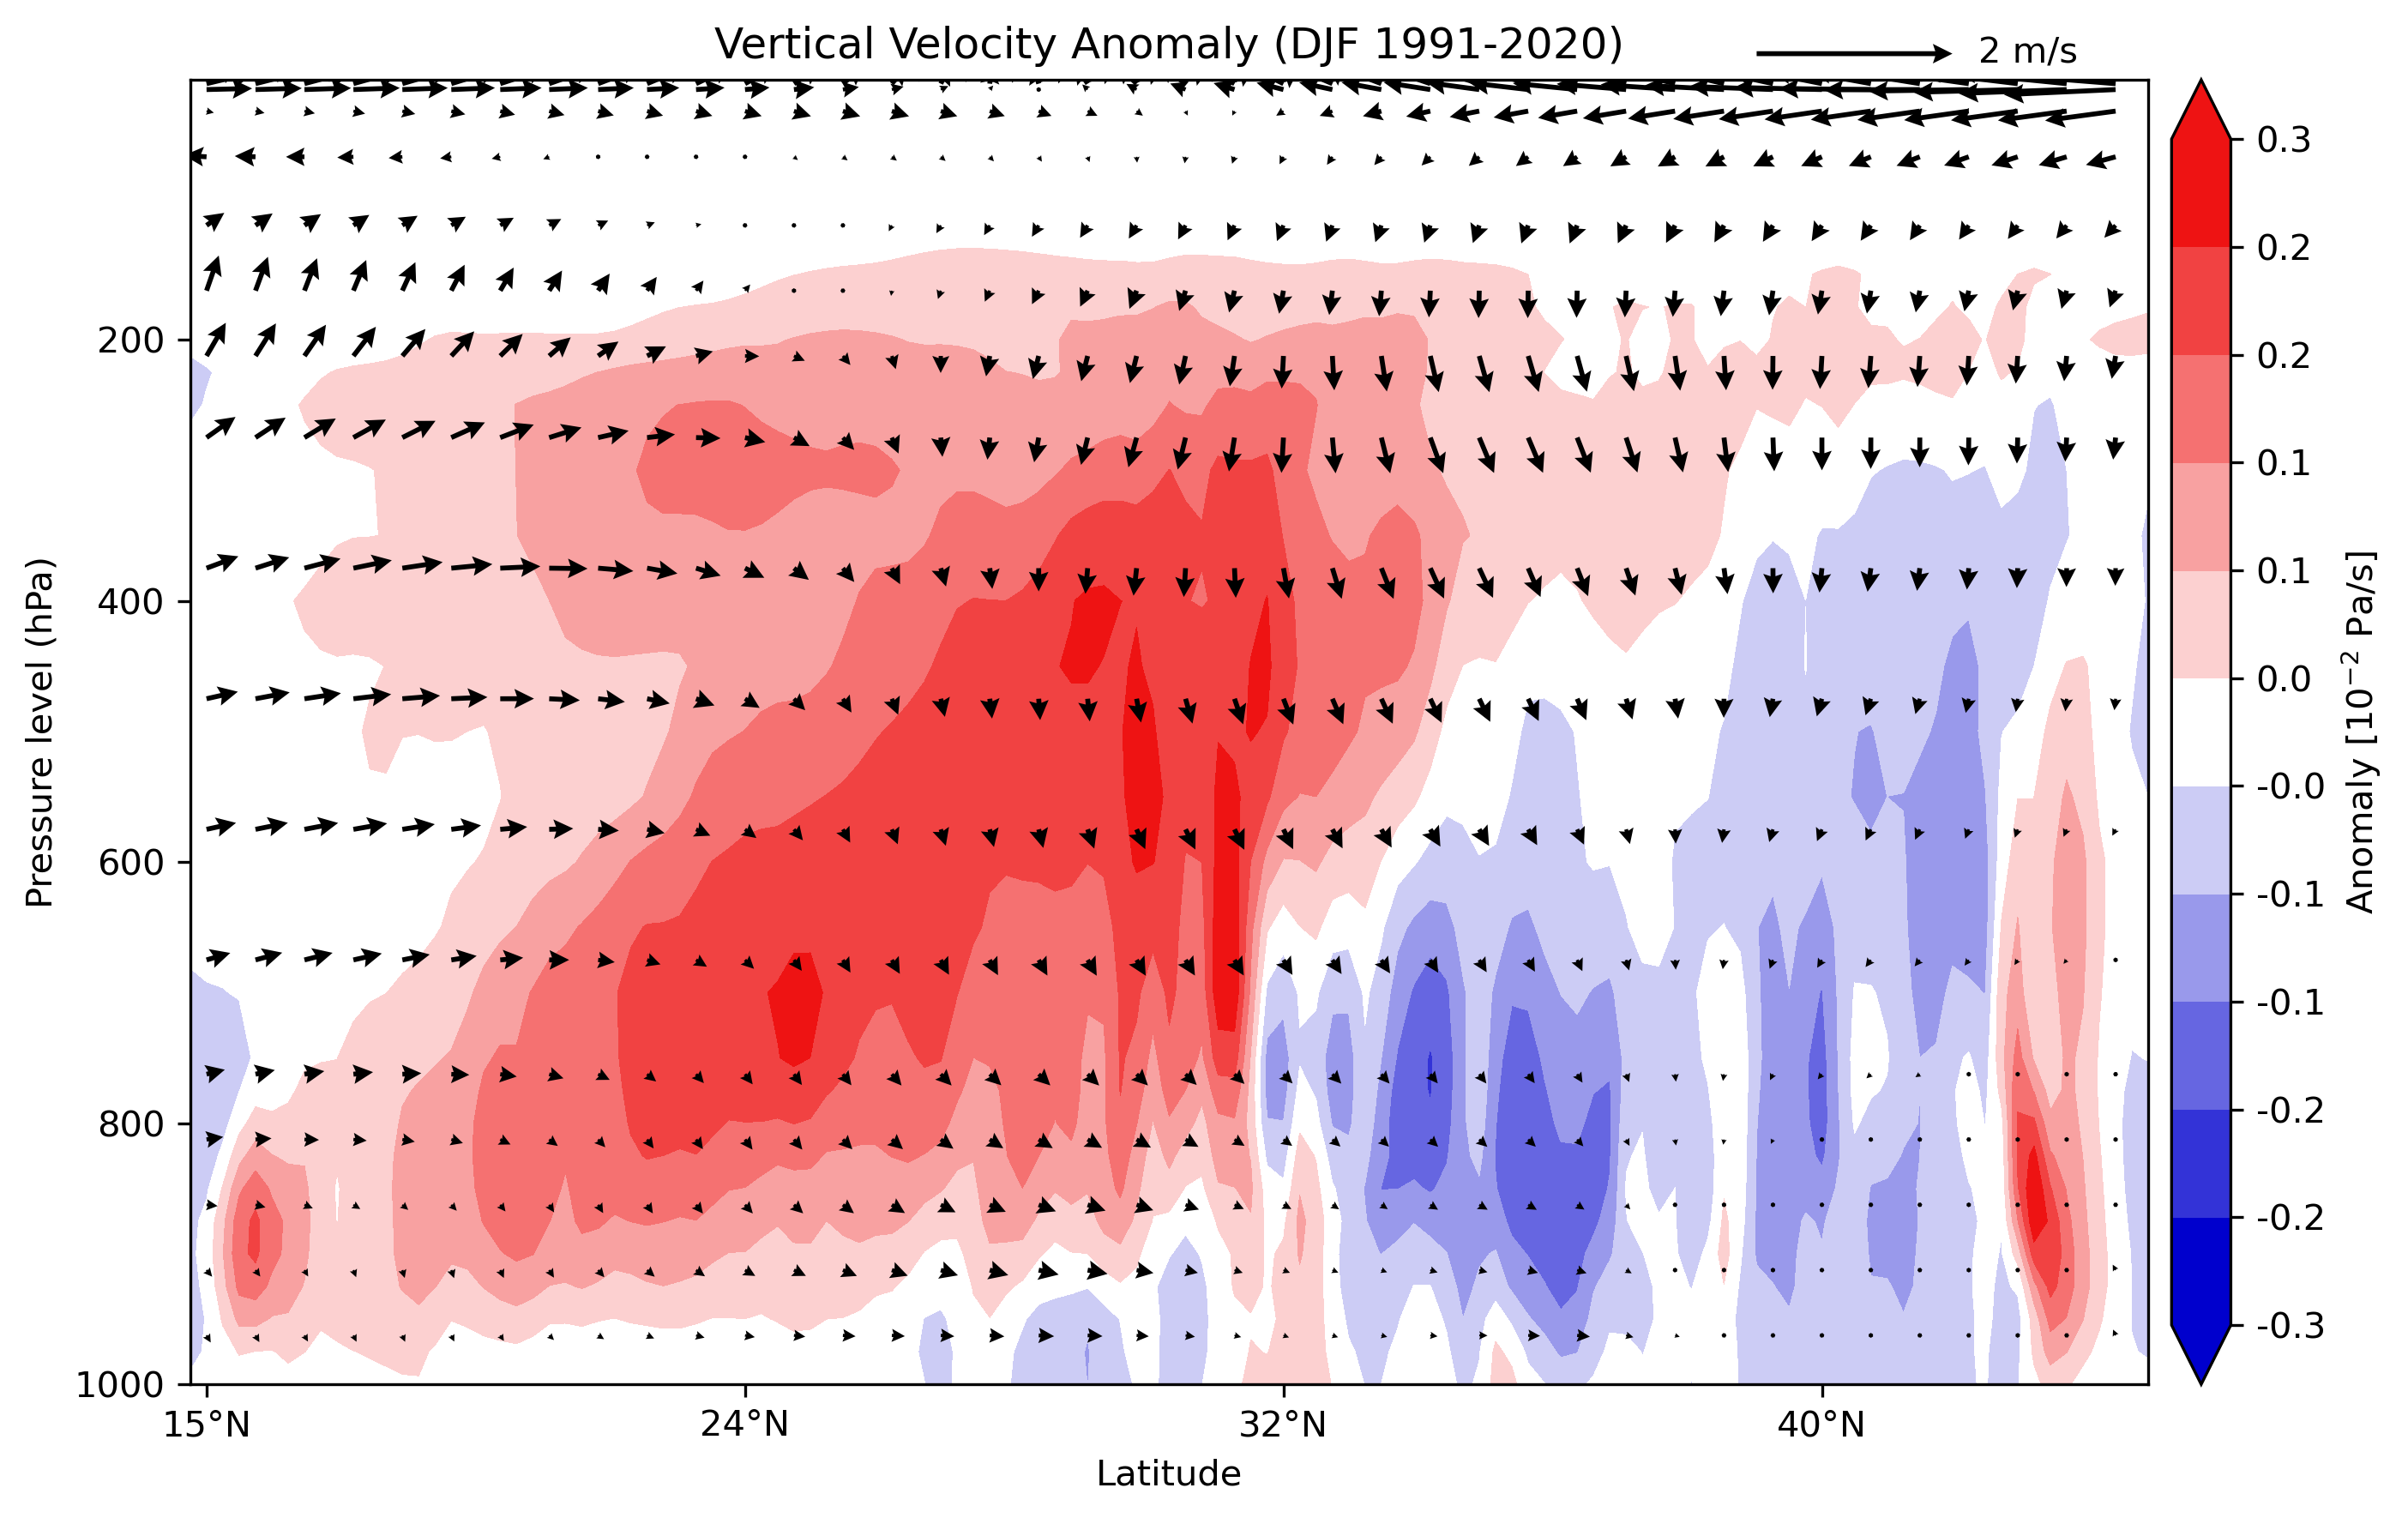

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Mean meridional wind anomaly over longitude
#wds_mean = anomaly_ds.mean(dim='longitude')
#uds_mean = uanomaly_ds.mean(dim='longitude')
#vds_mean = vanomaly_ds.mean(dim='longitude')
#pval_mean = pval_ds.mean(dim='longitude')

# Extract dates that are DJF and within 1991–2020
djf_dates = [d for d in anomaly_ds['date'].values if d.startswith('DJF') and 1991 <= int(d.split('_')[1]) <= 2020]

# Subset and average over time (date)
w_djf = anomaly_ds['w_anomaly'].sel(date=djf_dates).mean(dim='date')
u_djf = uanomaly_ds['u_anomaly'].sel(date=djf_dates).mean(dim='date')
v_djf = vanomaly_ds['v_anomaly'].sel(date=djf_dates).mean(dim='date')
# Average over longitude
w_djf = w_djf.mean(dim='longitude') * 100
u_djf = u_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()
v_djf = v_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

#w_djf2023 = wds_mean['w_anomaly'].sel(date='DJF_2021')
#u_djf2023 = uds_mean['u_anomaly'].sel(date='DJF_2021')
#v_djf2023 = vds_mean['v_anomaly'].sel(date='DJF_2021')
#pval_djf2023 = pval_mean.sel(date='DJF_2021')
#significant_mask = (pval_djf2023 < 0.05)

# Optional: round data values (for cleaner contours) and reduce arrow density:
#w_djf2023 = w_djf2023.round(2)
#w_djf2023 = w_djf2023.coarsen(latitude=1, pressure_level=1, boundary='trim').mean()
#u_djf2023 = u_djf2023.coarsen(latitude=3, pressure_level=2,boundary='trim').mean()
#v_djf2023 = v_djf2023.coarsen(latitude=3, pressure_level=2,boundary='trim').mean()
#pval_djf2023 = pval_djf2023.coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

# Set contour levels (fewer colors)
abs_max = np.nanmax(np.abs(w_djf))
vmin = -abs_max
vmax = abs_max
levels = np.linspace(vmin, vmax,12)  # Reduce number of levels

# Custom colormap: Royal Blue -> White -> Red
colors = ['#0000CD', '#FFFFFF', '#ee1313']
custom_cmap = LinearSegmentedColormap.from_list("RoyalRed", colors, N=len(levels)-1)

#colors = ['#0000CD', '#FFFFFF', '#B22222']  # MediumBlue → White → FireBrick
#custom_cmap = LinearSegmentedColormap.from_list("StrongRedBlue", colors, N=len(levels)-1)
# Plotting
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

cf = ax.contourf(
    w_djf['latitude'],
    w_djf['pressure_level'],
    w_djf.transpose('pressure_level', 'latitude'),
    levels=levels,
    cmap=custom_cmap,
    extend='both'
)

# Define lat & pressure grid for quiver
lat = u_djf['latitude'].values
plev = u_djf['pressure_level'].values
# Create 2D meshgrid
LAT, PLEV = np.meshgrid(lat, plev)
# Overlay quiver
Q = ax.quiver(
    LAT, PLEV,
    u_djf.transpose('pressure_level', 'latitude'),# Zonal component 
    v_djf.transpose('pressure_level', 'latitude'), # Meridional component
    scale=20,  # Adjust as needed for arrow length
    width=0.0025,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)
ax.invert_yaxis()
ax.quiverkey(Q, 0.9, 1.02, 2, '2 m/s', labelpos='E', coordinates='axes')

# Use xarray to get the coordinates of significant points (no shape mismatch)
#sig_mask = significant_mask.where(significant_mask, drop=True)
#sig_mask = sig_mask.stack(points=('pressure_level', 'latitude'))
#lat_points = sig_mask['latitude'].values
#plev_points = sig_mask['pressure_level'].values

#Overlay significant grid points
#ax.scatter(lat_points, plev_points,color='green', s=5, marker='o',label='p < 0.05')

# Axis labels and title
ax.set_xlabel('Latitude')
ax.set_ylabel('Pressure level (hPa)')
ax.set_title('Vertical Velocity Anomaly (DJF 1991-2020)')
# Add colorbar with 1 decimal formatting
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.01, format='%.1f')
cbar.set_ticks(np.linspace(vmin, vmax, 12))
cbar.set_label(r'Anomaly [$10^{-2}$ Pa/s]') # Adjust units if needed

#Format x-ticks also
#w_djf = wds_mean['w_anomaly'].sel(date='SON_2020')
#latitudes = w_djf['latitude'].values
ax.set_xticks(lat[::11])  # e.g., every 20th latitude value for readability
ax.set_xticklabels([
    f'{abs(l):.0f}°{"N" if l > 0 else "S" if l < 0 else ""}' for l in lat[::11]
])

# Improve layout
plt.tight_layout()
plt.show()


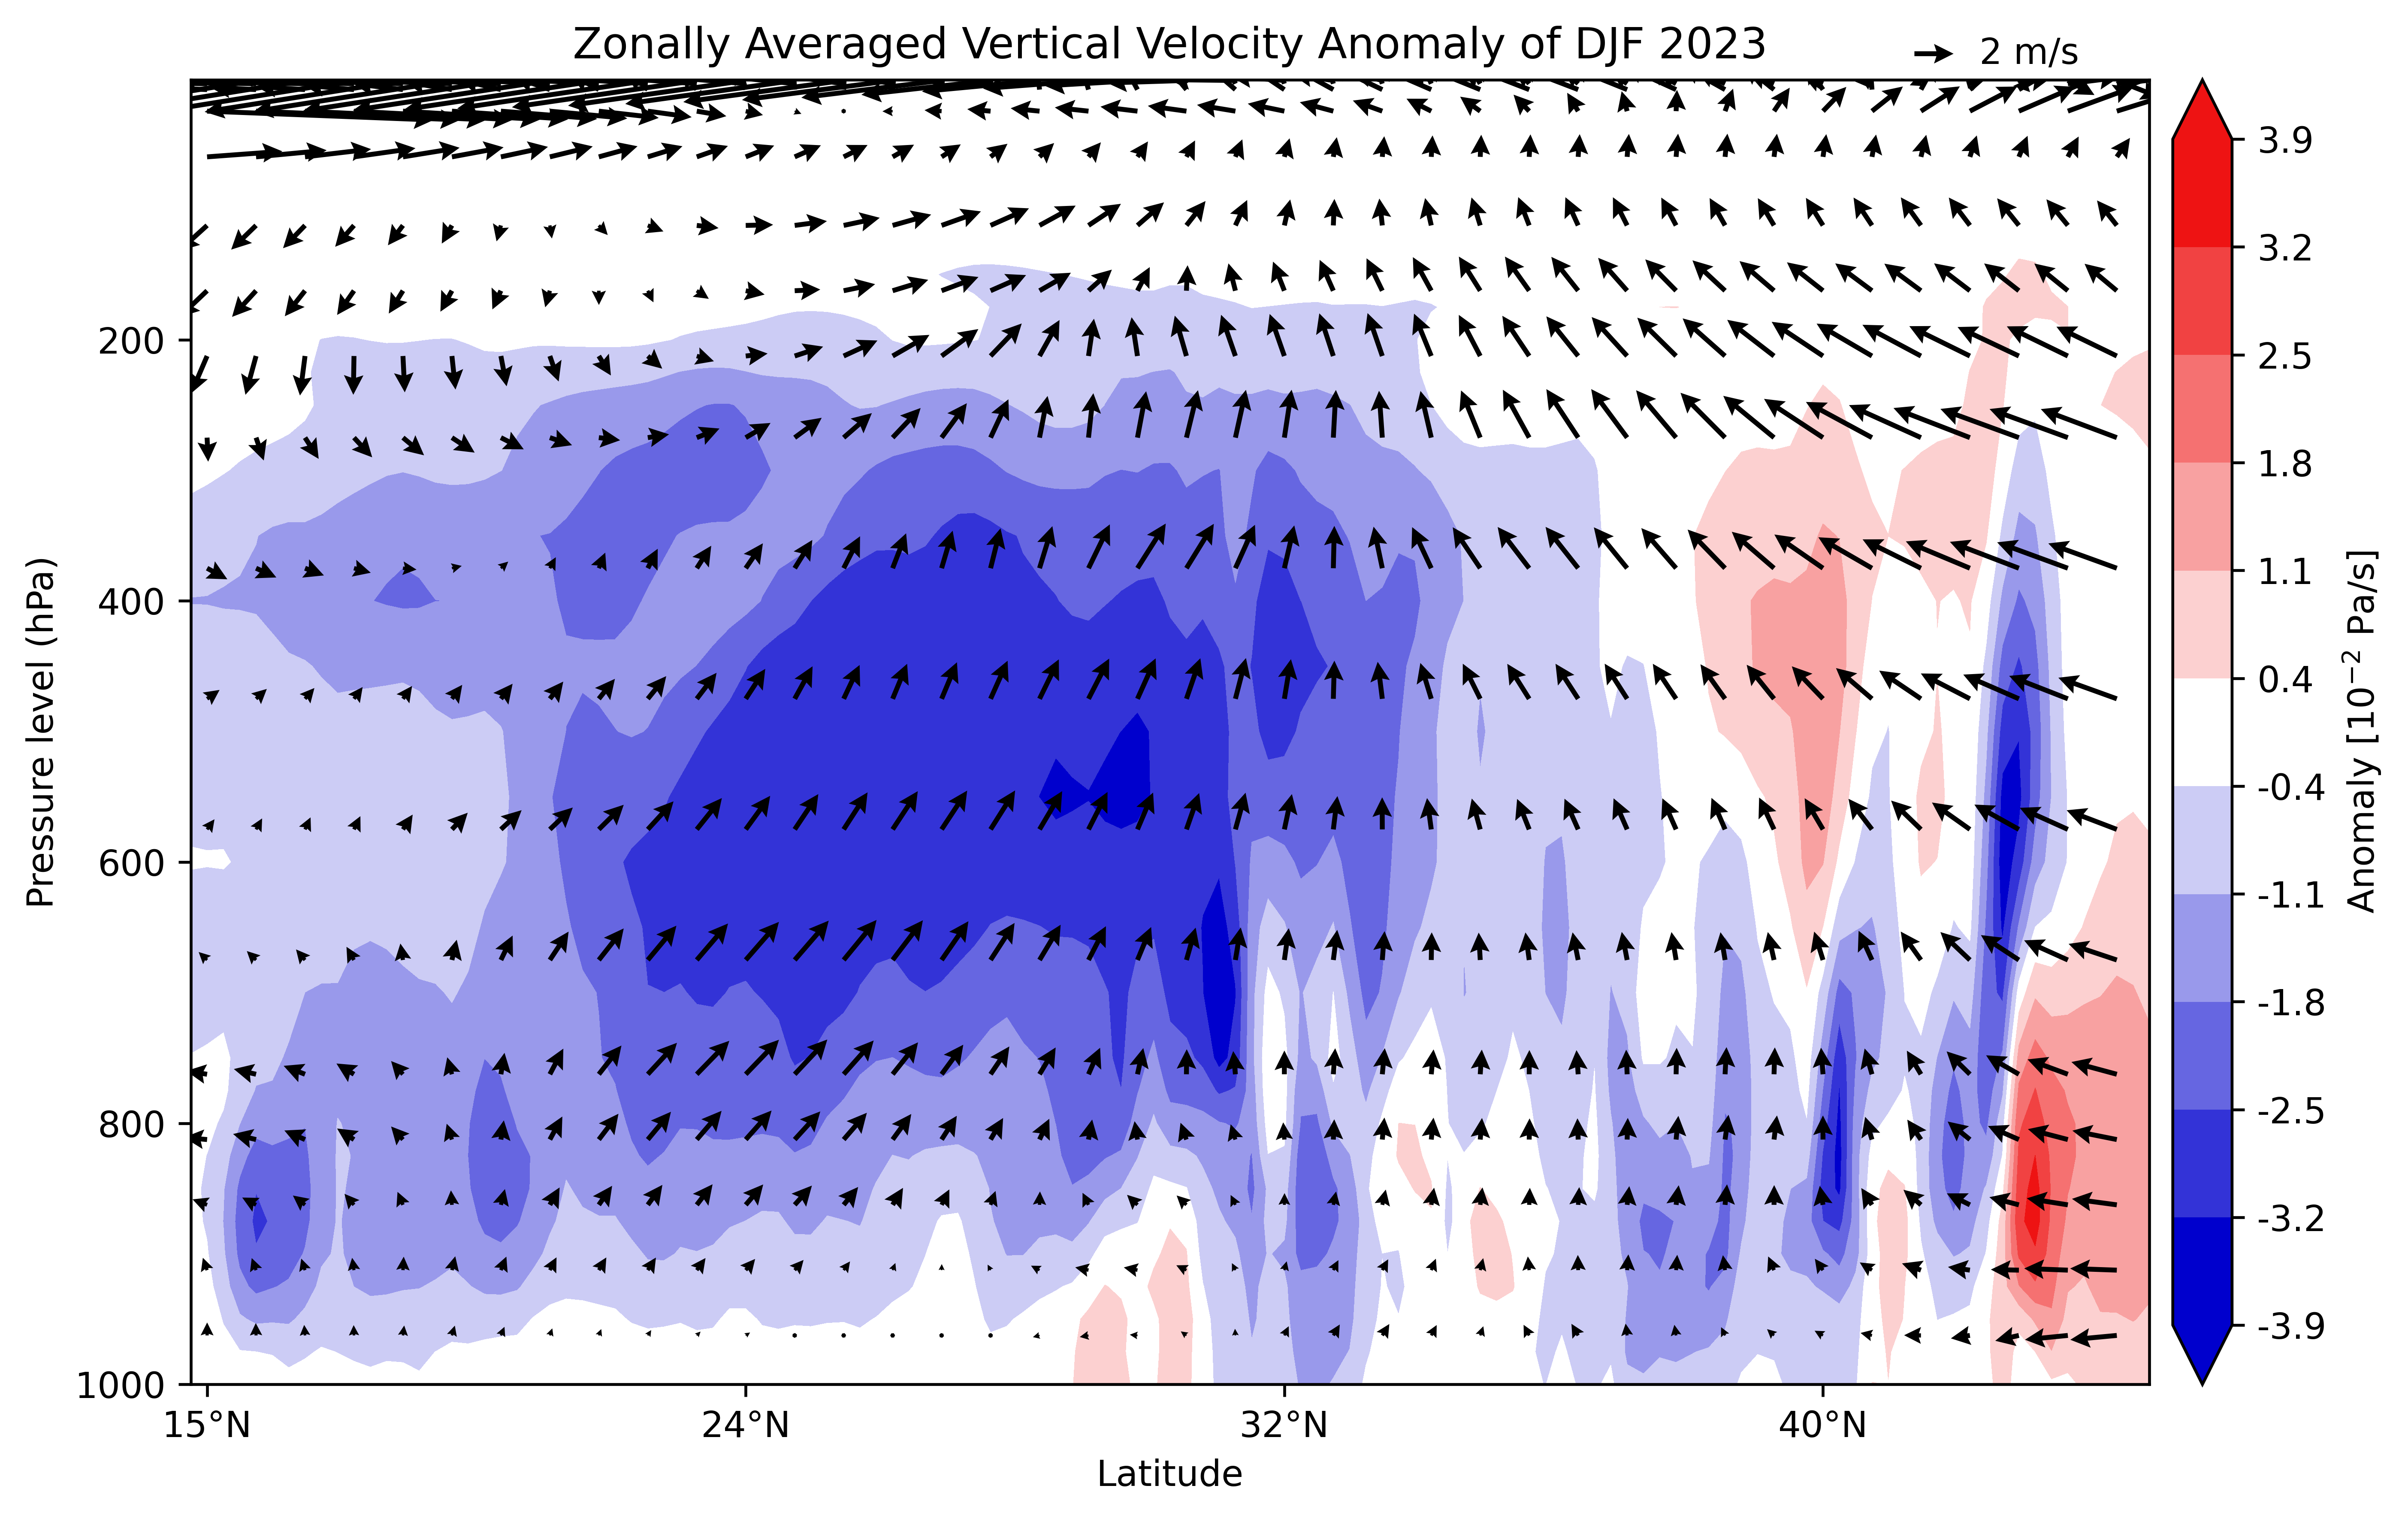

In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Mean meridional wind anomaly over longitude
wds_mean = anomaly_ds.mean(dim='longitude')
uds_mean = uanomaly_ds.mean(dim='longitude')
vds_mean = vanomaly_ds.mean(dim='longitude')
pval_mean = pval_ds.mean(dim='longitude')

# Subset and average over time (date)
w_djf = anomaly_ds['w_anomaly'].sel(date='DJF_2023')
u_djf = uanomaly_ds['u_anomaly'].sel(date='DJF_2023')
v_djf = vanomaly_ds['v_anomaly'].sel(date='DJF_2023')

# Average over longitude
w_djf = w_djf.mean(dim='longitude') * 100
u_djf = u_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()
v_djf = v_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

# Set contour levels (fewer colors)
abs_max = np.nanmax(np.abs(w_djf))
vmin = -abs_max
vmax = abs_max
levels = np.linspace(vmin, vmax,12)  # Reduce number of levels

# Custom colormap: Royal Blue -> White -> Red
colors = ['#0000CD', '#FFFFFF', '#ee1313']
custom_cmap = LinearSegmentedColormap.from_list("RoyalRed", colors, N=len(levels)-1)

#colors = ['#0000CD', '#FFFFFF', '#B22222']  # MediumBlue → White → FireBrick
#custom_cmap = LinearSegmentedColormap.from_list("StrongRedBlue", colors, N=len(levels)-1)
# Plotting
fig, ax = plt.subplots(figsize=(10, 6), dpi=600)

cf = ax.contourf(
    w_djf['latitude'],
    w_djf['pressure_level'],
    w_djf.transpose('pressure_level', 'latitude'),
    levels=levels,
    cmap=custom_cmap,
    extend='both'
)

# Define lat & pressure grid for quiver
lat = u_djf['latitude'].values
plev = u_djf['pressure_level'].values
# Create 2D meshgrid
LAT, PLEV = np.meshgrid(lat, plev)
# Overlay quiver
Q = ax.quiver(
    LAT, PLEV,
    u_djf.transpose('pressure_level', 'latitude'),# Zonal component 
    v_djf.transpose('pressure_level', 'latitude'), # Meridional component
    scale=100,  # Adjust as needed for arrow length
    width=0.0025,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)
ax.invert_yaxis()
ax.quiverkey(Q, 0.9, 1.02, 2, '2 m/s', labelpos='E', coordinates='axes')

# Use xarray to get the coordinates of significant points (no shape mismatch)
#sig_mask = significant_mask.where(significant_mask, drop=True)
#sig_mask = sig_mask.stack(points=('pressure_level', 'latitude'))
#lat_points = sig_mask['latitude'].values
#plev_points = sig_mask['pressure_level'].values

#Overlay significant grid points
#ax.scatter(lat_points, plev_points,color='green', s=5, marker='o',label='p < 0.05')

# Axis labels and title
ax.set_xlabel('Latitude')
ax.set_ylabel('Pressure level (hPa)')
ax.set_title('Zonally Averaged Vertical Velocity Anomaly of DJF 2023')
# Add colorbar with 1 decimal formatting
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.01, format='%.1f')
cbar.set_ticks(np.linspace(vmin, vmax, 12))
cbar.set_label(r'Anomaly [$10^{-2}$ Pa/s]') # Adjust units if needed

#Format x-ticks also
#w_djf = wds_mean['w_anomaly'].sel(date='SON_2020')
#latitudes = w_djf['latitude'].values
ax.set_xticks(lat[::11])  # e.g., every 20th latitude value for readability
ax.set_xticklabels([
    f'{abs(l):.0f}°{"N" if l > 0 else "S" if l < 0 else ""}' for l in lat[::11]
])

# Improve layout
plt.tight_layout()
plt.show()


In [24]:
fig.savefig(f"VV Anomaly DJF 2023.png", dpi=600, bbox_inches="tight", format="png")